In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import polars as pl
import seaborn as sns

In [4]:
inputs_dir = "../1_inputs"
outputs_dir = "../3_outputs"
metadata_outputs = "../../1_allele_collection/3_outputs"

In [5]:
scores = pd.read_csv(f"{outputs_dir}/assay_scores.csv")
scores

,symbol,aa_change,ensembl_gene_id,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,abun_score,misloc_score,ppi_score,ai_score,rsa_f32,plddt_f32,abun_hit,misloc_hit,ppi_hit,ai_hit,any_hit_no_ai,any_hit
0,GFAP,Arg88Cys,ENSG00000131095,1_Pathogenic,NaN,2.0,GFAP_Arg88Cys,NaN,NaN,0.379350,0.78805,-0.653226,95.35,NaN,NaN,False,True,False,True
1,MLH1,Cys39Phe,ENSG00000076242,4_VUS,NaN,3.0,MLH1_Cys39Phe,NaN,NaN,0.685366,0.92384,-0.022222,94.17,NaN,NaN,True,True,True,True
2,NMNAT1,Arg237Leu,ENSG00000173614,1_Pathogenic,NaN,NaN,NMNAT1_Arg237Leu,10.828229,0.993834,0.759060,0.54925,-0.508065,98.06,True,True,True,False,True,True
3,KCNJ2,Glu349Lys,ENSG00000123700,3_Conflicting,1.299710e-05,1.0,KCNJ2_Glu349Lys,3.066933,NaN,0.662913,0.38882,-0.737113,97.03,True,NaN,True,False,True,True
4,STXBP1,Arg406His,ENSG00000136854,1_Pathogenic,NaN,2.0,STXBP1_Arg406His,5.727526,NaN,0.653516,0.96096,-0.036290,98.52,True,NaN,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1379,TH,Leu205Pro,ENSG00000180176,1_Pathogenic,NaN,2.0,TH_Leu205Pro,0.872532,0.647859,0.377595,0.79931,-0.597561,95.75,False,False,False,True,False,True
1380,AGXT,Arg233Leu,ENSG00000172482,1_Pathogenic,6.844330e-07,1.0,AGXT_Arg233Leu,1.033663,NaN,NaN,0.75347,-0.100806,98.53,False,NaN,NaN,True,False,True
1381,LITAF,Gly130Ser,ENSG00000189067,4_VUS,NaN,1.0,LITAF_Gly130Ser,NaN,NaN,0.247672,0.83356,-0.476190,70.83,NaN,NaN,False,True,False,True
1382,KCNJ2,Arg325Cys,ENSG00000123700,3_Conflicting,5.677670e-05,1.0,KCNJ2_Arg325Cys,2.431285,NaN,0.662913,0.77483,-0.431452,97.58,True,NaN,True,True,True,True


<Axes: ylabel='Frequency'>

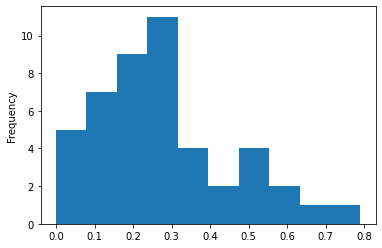

In [6]:
scores[scores.clinvar_clnsig_clean == '2_Benign'].ppi_score.plot(kind='hist')

In [7]:
import math
import numpy as np

# Using math.dist()
p1 = [4, 5, 6]
p2 = [4, 5, 6]
distance = math.dist(p1, p2)
print(f"Euclidean distance using math.dist(): {distance}")

# Using NumPy
p1 = np.array([1, 2, 3])
p2 = np.array([4, 5, 6])
distance = np.linalg.norm(p1 - p2)
print(f"Euclidean distance using NumPy: {distance}")

# Using Scipy
from scipy.spatial import distance
p1 = [1, 2, 3]
p2 = [4, 5, 6]
distance = distance.euclidean(p1, p2)
print(f"Euclidean distance using Scipy: {distance}")

Euclidean distance using math.dist(): 0.0
Euclidean distance using NumPy: 5.196152422706632
Euclidean distance using Scipy: 5.196152422706632


<Axes: ylabel='Frequency'>

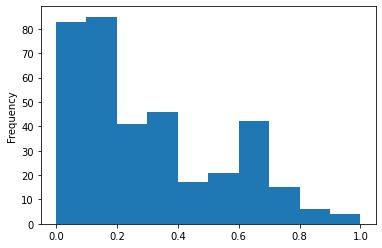

In [8]:
scores[scores.clinvar_clnsig_clean == '1_Pathogenic'].ppi_score.plot(kind='hist')

In [9]:
scores

,symbol,aa_change,ensembl_gene_id,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,abun_score,misloc_score,ppi_score,ai_score,rsa_f32,plddt_f32,abun_hit,misloc_hit,ppi_hit,ai_hit,any_hit_no_ai,any_hit
0,GFAP,Arg88Cys,ENSG00000131095,1_Pathogenic,NaN,2.0,GFAP_Arg88Cys,NaN,NaN,0.379350,0.78805,-0.653226,95.35,NaN,NaN,False,True,False,True
1,MLH1,Cys39Phe,ENSG00000076242,4_VUS,NaN,3.0,MLH1_Cys39Phe,NaN,NaN,0.685366,0.92384,-0.022222,94.17,NaN,NaN,True,True,True,True
2,NMNAT1,Arg237Leu,ENSG00000173614,1_Pathogenic,NaN,NaN,NMNAT1_Arg237Leu,10.828229,0.993834,0.759060,0.54925,-0.508065,98.06,True,True,True,False,True,True
3,KCNJ2,Glu349Lys,ENSG00000123700,3_Conflicting,1.299710e-05,1.0,KCNJ2_Glu349Lys,3.066933,NaN,0.662913,0.38882,-0.737113,97.03,True,NaN,True,False,True,True
4,STXBP1,Arg406His,ENSG00000136854,1_Pathogenic,NaN,2.0,STXBP1_Arg406His,5.727526,NaN,0.653516,0.96096,-0.036290,98.52,True,NaN,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1379,TH,Leu205Pro,ENSG00000180176,1_Pathogenic,NaN,2.0,TH_Leu205Pro,0.872532,0.647859,0.377595,0.79931,-0.597561,95.75,False,False,False,True,False,True
1380,AGXT,Arg233Leu,ENSG00000172482,1_Pathogenic,6.844330e-07,1.0,AGXT_Arg233Leu,1.033663,NaN,NaN,0.75347,-0.100806,98.53,False,NaN,NaN,True,False,True
1381,LITAF,Gly130Ser,ENSG00000189067,4_VUS,NaN,1.0,LITAF_Gly130Ser,NaN,NaN,0.247672,0.83356,-0.476190,70.83,NaN,NaN,False,True,False,True
1382,KCNJ2,Arg325Cys,ENSG00000123700,3_Conflicting,5.677670e-05,1.0,KCNJ2_Arg325Cys,2.431285,NaN,0.662913,0.77483,-0.431452,97.58,True,NaN,True,True,True,True


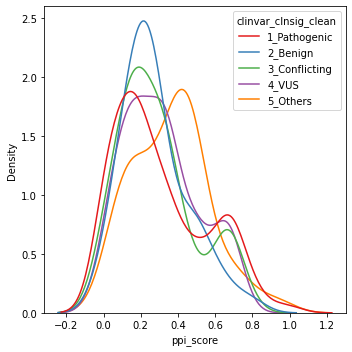

In [10]:
# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(figsize=(5, 5)) ## , sharey=True
hue_order = sorted(scores["clinvar_clnsig_clean"].dropna().unique())
# Loop through variables and create subplots

sns.kdeplot(
    data=scores,
    x='ppi_score',
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    palette="Set1",
    common_norm=False
)
# ax.set_title(var)
plt.tight_layout()
plt.show()

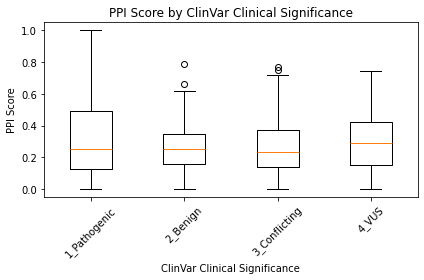

In [11]:
import matplotlib.pyplot as plt

# Prepare data
df2 = scores.dropna(subset=['ppi_score', 'clinvar_clnsig_clean'])
categories = ['1_Pathogenic', '2_Benign', '3_Conflicting', '4_VUS']
data = [df2[df2['clinvar_clnsig_clean'] == cat]['ppi_score'] for cat in categories]

# Plot
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(data)
ax.set_xticklabels(categories, rotation=45)
ax.set_xlabel('ClinVar Clinical Significance')
ax.set_ylabel('PPI Score')
ax.set_title('PPI Score by ClinVar Clinical Significance')
plt.tight_layout()
plt.show()


In [12]:
inheritance_mapping_df = pd.read_csv(f'{metadata_outputs}/inheritance_mapping.csv')
inheritance_mapping_df['allele_0'] = [f"{symbol}_{aa}" for symbol, aa in zip(inheritance_mapping_df.symbol, inheritance_mapping_df.aa_change)]
inheritance_dict = inheritance_mapping_df.set_index('allele_0')['inheritance_clean'].to_dict()
inheritance_dict

{'GBA_Val54Leu': nan,
 'GBA_Leu224Phe': nan,
 'GBA_Arg296Gln': 'Conflicting',
 'GBA_Leu483Pro': 'Conflicting',
 'SLC9A3R1_Leu110Val': 'Autosomal dominant',
 'SLC9A3R1_Arg153Gln': 'Autosomal dominant',
 'MYD88_Leu93Pro': 'Autosomal recessive',
 'MYD88_Arg196Cys': 'Autosomal recessive',
 'ACTA2_Arg39His': 'Autosomal dominant',
 'ACTA2_Asn117Thr': nan,
 'ACTA2_Arg212Gln': 'Autosomal dominant',
 'ACTA2_Arg292Gly': nan,
 'FOXA3_Gly91Arg': nan,
 'RFX5_Arg149Gln': 'Autosomal recessive',
 'HYLS1_Asp198Gly': 'Autosomal recessive',
 'ALDOA_Asp129Gly': 'Autosomal recessive',
 'ALDOA_Glu207Lys': 'Autosomal recessive',
 'ALDOA_Cys339Tyr': 'Autosomal recessive',
 'CTH_Thr67Ile': 'Autosomal recessive',
 'CTH_Gln240Glu': 'Autosomal recessive',
 'CTH_Ser403Ile': 'Autosomal recessive',
 'PEPD_Arg184Gln': 'Autosomal recessive',
 'PEPD_Ser202Phe': 'Autosomal recessive',
 'PEPD_Asp276Asn': 'Autosomal recessive',
 'PEPD_Gly448Arg': 'Autosomal recessive',
 'MVK_His20Gln': 'Autosomal recessive',
 'MVK_Pro167L

In [13]:
scores['inheritance'] = scores['allele_0'].map(inheritance_dict)
scores

,symbol,aa_change,ensembl_gene_id,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,abun_score,misloc_score,ppi_score,ai_score,rsa_f32,plddt_f32,abun_hit,misloc_hit,ppi_hit,ai_hit,any_hit_no_ai,any_hit,inheritance
0,GFAP,Arg88Cys,ENSG00000131095,1_Pathogenic,NaN,2.0,GFAP_Arg88Cys,NaN,NaN,0.379350,0.78805,-0.653226,95.35,NaN,NaN,False,True,False,True,Autosomal dominant
1,MLH1,Cys39Phe,ENSG00000076242,4_VUS,NaN,3.0,MLH1_Cys39Phe,NaN,NaN,0.685366,0.92384,-0.022222,94.17,NaN,NaN,True,True,True,True,Autosomal dominant
2,NMNAT1,Arg237Leu,ENSG00000173614,1_Pathogenic,NaN,NaN,NMNAT1_Arg237Leu,10.828229,0.993834,0.759060,0.54925,-0.508065,98.06,True,True,True,False,True,True,Autosomal recessive
3,KCNJ2,Glu349Lys,ENSG00000123700,3_Conflicting,1.299710e-05,1.0,KCNJ2_Glu349Lys,3.066933,NaN,0.662913,0.38882,-0.737113,97.03,True,NaN,True,False,True,True,Autosomal dominant
4,STXBP1,Arg406His,ENSG00000136854,1_Pathogenic,NaN,2.0,STXBP1_Arg406His,5.727526,NaN,0.653516,0.96096,-0.036290,98.52,True,NaN,True,True,True,True,Conflicting
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1379,TH,Leu205Pro,ENSG00000180176,1_Pathogenic,NaN,2.0,TH_Leu205Pro,0.872532,0.647859,0.377595,0.79931,-0.597561,95.75,False,False,False,True,False,True,Autosomal recessive
1380,AGXT,Arg233Leu,ENSG00000172482,1_Pathogenic,6.844330e-07,1.0,AGXT_Arg233Leu,1.033663,NaN,NaN,0.75347,-0.100806,98.53,False,NaN,NaN,True,False,True,Autosomal recessive
1381,LITAF,Gly130Ser,ENSG00000189067,4_VUS,NaN,1.0,LITAF_Gly130Ser,NaN,NaN,0.247672,0.83356,-0.476190,70.83,NaN,NaN,False,True,False,True,NaN
1382,KCNJ2,Arg325Cys,ENSG00000123700,3_Conflicting,5.677670e-05,1.0,KCNJ2_Arg325Cys,2.431285,NaN,0.662913,0.77483,-0.431452,97.58,True,NaN,True,True,True,True,Autosomal dominant


# all plots

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1939239717.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


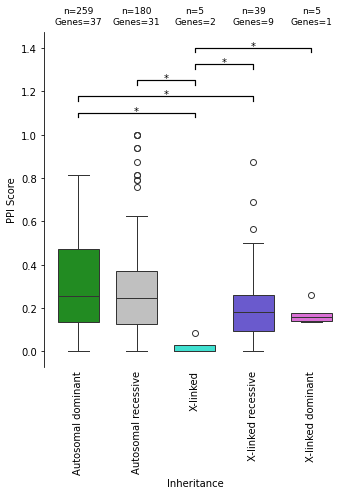

In [14]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests


order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'
]

score = 'ppi_score'

palette = dict(zip(order, box_colors))


df_plot = scores.dropna(subset=score)


# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='inheritance', y=score,
    data=df_plot, order=order, ax=ax,# showfliers=False,
    width=0.70, palette=palette, saturation=1
)
# sns.swarmplot(
#     x='inheritance', y='abun_score',
#     data=df_plot, order=order,
#     color='black', alpha=0.5, size=4, ax=ax, 
#     edgecolor='black', linewidth=1, palette=palette
# )

ax.set_xlabel('Inheritance')
ax.set_ylabel('PPI Score')
ax.tick_params(axis='x', rotation=90)


# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.inheritance==g1, score]
    y = df_plot.loc[df_plot.inheritance==g2, score]
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot[score].max()
y_min = df_plot[score].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.inheritance == cat]
    n_edges = len(sub)
    n_genes = sub['symbol'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

In [15]:
for a, b in zip(all_pairs, p_adj):
    print(a,b)

('Autosomal dominant', 'Autosomal recessive') 0.1091319158502219
('Autosomal dominant', 'X-linked') 0.0067756437769622485
('Autosomal dominant', 'X-linked recessive') 0.01624029597298982
('Autosomal dominant', 'X-linked dominant') 0.23098102624758823
('Autosomal recessive', 'X-linked') 0.0071966968491171185
('Autosomal recessive', 'X-linked recessive') 0.09274571640360732
('Autosomal recessive', 'X-linked dominant') 0.3238594839012838
('X-linked', 'X-linked recessive') 0.01624029597298982
('X-linked', 'X-linked dominant') 0.02231885056582951
('X-linked recessive', 'X-linked dominant') 0.8822161874095985


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1185517181.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


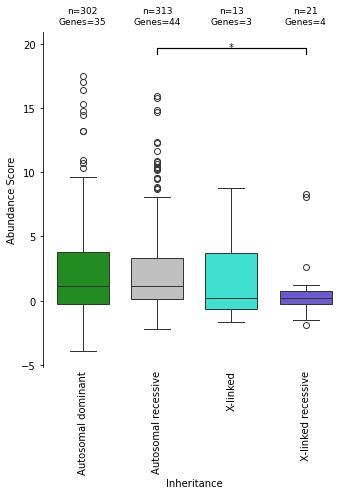

In [16]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
]

score = 'abun_score'

palette = dict(zip(order, box_colors))


df_plot = scores.dropna(subset=score)


# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='inheritance', y=score,
    data=df_plot, order=order, ax=ax,# showfliers=False,
    width=0.70, palette=palette, saturation=1
)
# sns.swarmplot(
#     x='inheritance', y='abun_score',
#     data=df_plot, order=order,
#     color='black', alpha=0.5, size=4, ax=ax, 
#     edgecolor='black', linewidth=1, palette=palette
# )

ax.set_xlabel('Inheritance')
ax.set_ylabel('Abundance Score')
ax.tick_params(axis='x', rotation=90)


# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.inheritance==g1, score]
    y = df_plot.loc[df_plot.inheritance==g2, score]
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot[score].max()
y_min = df_plot[score].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.inheritance == cat]
    n_edges = len(sub)
    n_genes = sub['symbol'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

In [17]:
for a, b in zip(all_pairs, p_adj):
    print(a,b)

('Autosomal dominant', 'Autosomal recessive') 0.4110414540939677
('Autosomal dominant', 'X-linked') 0.6248670137753041
('Autosomal dominant', 'X-linked recessive') 0.2159802931808259
('Autosomal recessive', 'X-linked') 0.4110414540939677
('Autosomal recessive', 'X-linked recessive') 0.035757849812679175
('X-linked', 'X-linked recessive') 0.8040806574719614


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/3680526217.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


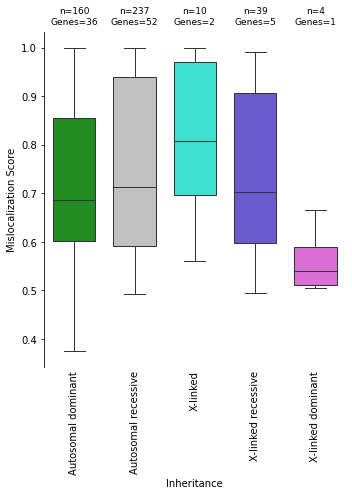

In [18]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests


order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'
]

score = 'misloc_score'

palette = dict(zip(order, box_colors))


df_plot = scores.dropna(subset=score)


# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='inheritance', y=score,
    data=df_plot, order=order, ax=ax,# showfliers=False,
    width=0.70, palette=palette, saturation=1
)
# sns.swarmplot(
#     x='inheritance', y='abun_score',
#     data=df_plot, order=order,
#     color='black', alpha=0.5, size=4, ax=ax, 
#     edgecolor='black', linewidth=1, palette=palette
# )

ax.set_xlabel('Inheritance')
ax.set_ylabel('Mislocalization Score')
ax.tick_params(axis='x', rotation=90)


# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.inheritance==g1, score]
    y = df_plot.loc[df_plot.inheritance==g2, score]
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot[score].max()
y_min = df_plot[score].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.inheritance == cat]
    n_edges = len(sub)
    n_genes = sub['symbol'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

In [19]:
for a, b in zip(all_pairs, p_adj):
    print(a,b)

('Autosomal dominant', 'Autosomal recessive') 0.2363582171802124
('Autosomal dominant', 'X-linked') 0.17625872750823077
('Autosomal dominant', 'X-linked recessive') 0.2721557012100531
('Autosomal dominant', 'X-linked dominant') 0.08361338563733653
('Autosomal recessive', 'X-linked') 0.2721557012100531
('Autosomal recessive', 'X-linked recessive') 0.7193106074254862
('Autosomal recessive', 'X-linked dominant') 0.07992007992007992
('X-linked', 'X-linked recessive') 0.29959172731021183
('X-linked', 'X-linked dominant') 0.07992007992007992
('X-linked recessive', 'X-linked dominant') 0.07992007992007992


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/3470718782.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


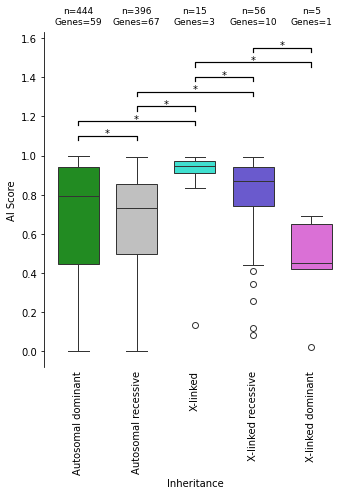

In [20]:
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]

box_colors = [
    'forestgreen',  # red
    'silver',  # orange
    'turquoise',  # yellow
    'slateblue',  # light blue
    'orchid',  # blue
    'firebrick'
]

score = 'ai_score'

palette = dict(zip(order, box_colors))


df_plot = scores.dropna(subset=score)


# 3) draw the box+strip
fig, ax = plt.subplots(figsize=(5,7))
sns.boxplot(
    x='inheritance', y=score,
    data=df_plot, order=order, ax=ax,# showfliers=False,
    width=0.70, palette=palette, saturation=1
)
# sns.swarmplot(
#     x='inheritance', y='abun_score',
#     data=df_plot, order=order,
#     color='black', alpha=0.5, size=4, ax=ax, 
#     edgecolor='black', linewidth=1, palette=palette
# )

ax.set_xlabel('Inheritance')
ax.set_ylabel('AI Score')
ax.tick_params(axis='x', rotation=90)


# 2) Compute all pairwise p‑values
all_pairs = list(combinations(order, 2))

pairs = [ (g1,g2) for g1,g2 in all_pairs if 'WT-like' in (g1,g2)]

raw_p = []
for g1, g2 in all_pairs:
    x = df_plot.loc[df_plot.inheritance==g1, score]
    y = df_plot.loc[df_plot.inheritance==g2, score]
    stat,p = mannwhitneyu(x, y, alternative='two-sided')
    raw_p.append(p)
# FDR correction
_, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')

# 3) Annotate significant all_pairs
pos = {cat:i for i,cat in enumerate(order)}
y_max = df_plot[score].max()
y_min = df_plot[score].min()
height = y_max + (y_max-y_min)*0.08  # baseline for brackets
step   = (y_max-y_min)*0.075          # vertical spacing per annotation
y_index = 0

for idx, ((g1,g2), pval) in enumerate(zip(all_pairs, p_adj)):    
    if pval < 0.05:
        x1, x2 = pos[g1], pos[g2]
        y = height + y_index*step
        # bracket
        ax.plot([x1, x1, x2, x2],
                [y, y+step*0.3, y+step*0.3, y],
                lw=1.2, c='k')
        ax.text((x1+x2)/2, y+step*0.1, "*",
                ha='center', va='bottom', color='k')
        y_index += 1

# 4) annotate edge‐counts and gene‐counts
y_min, y_max = ax.get_ylim()
yrange = y_max - y_min
y_counts = y_max + 0.02*yrange
    
for i, cat in enumerate(order):
    sub = df_plot[df_plot.inheritance == cat]
    n_edges = len(sub)
    n_genes = sub['symbol'].nunique()
    ax.text(
        i, y_counts,
        f"n={n_edges}\nGenes={n_genes}",
        ha='center', va='bottom', fontsize=9
    )
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)

ax.xaxis.set_tick_params(length=0)

plt.tight_layout()
plt.show()

# subplots

/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1327420734.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1327420734.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)


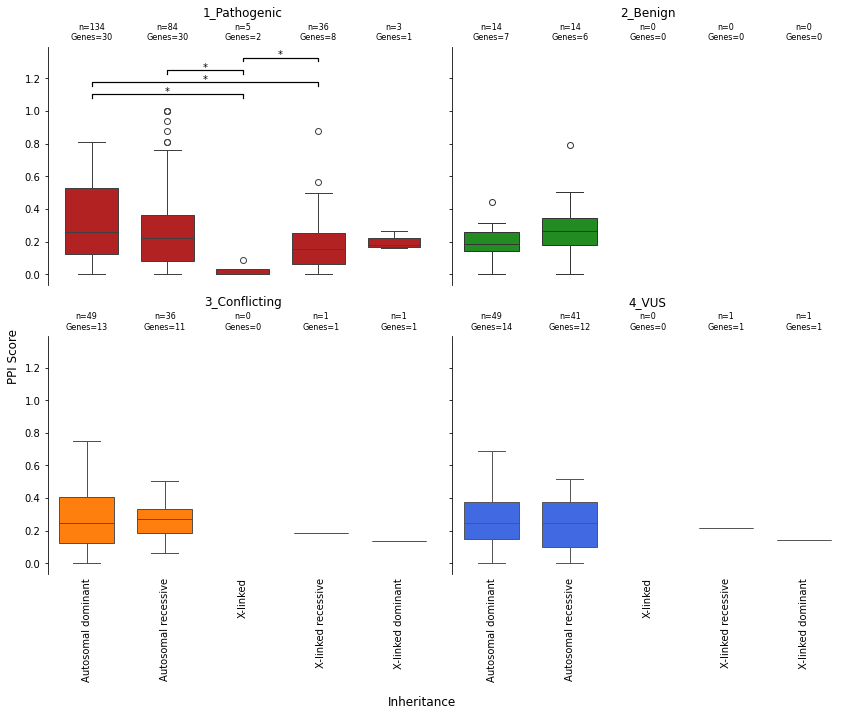

In [22]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

#--- parameters from your original snippet ---
order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]
box_colors = ['forestgreen','silver','turquoise','slateblue','orchid']
palette = dict(zip(order, box_colors))
score = 'ppi_score'

clinsig_colors = {
    '1_Pathogenic':   'firebrick',
    '2_Benign':       'forestgreen',
    '3_Conflicting':  'C1',
    '4_VUS':          'royalblue',
}

# drop global NaNs
df_clean = scores.dropna(subset=[score, 'clinvar_clnsig_clean'])

# figure layout
clin_cats = ['1_Pathogenic', '2_Benign',  '3_Conflicting', '4_VUS']
n = len(clin_cats)
ncols = 2
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, nrows*5), sharey=True)
axes = axes.flatten()

for idx, (ax, clin) in enumerate(zip(axes, clin_cats)):
    sub = df_clean[df_clean['clinvar_clnsig_clean']==clin]
    color = clinsig_colors[clin]
    # 1) boxplot
    sns.boxplot(
        x='inheritance', y=score, data=sub,
        order=order, color=color, width=0.7,
        saturation=1, ax=ax
    )
    ax.set_title(clin, pad=30)
    
    ax.set_xlabel('')  # supxlabel handles the axis label

    if idx < ncols:
        # first row: remove xtick labels entirely
        ax.set_xticklabels([])
    else:
        # bottom row: show & rotate them
        ax.set_xticklabels(order, rotation=90)
    
    # ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('')  # label only on first
    
    # 2) stats: all pairwise
    all_pairs = list(combinations(order, 2))
    raw_p = []
    for g1,g2 in all_pairs:
        x = sub.loc[sub.inheritance==g1, score]
        y = sub.loc[sub.inheritance==g2, score]
        # if either group is empty, skip
        if len(x)==0 or len(y)==0:
            raw_p.append(1.0)
        else:
            _, p = mannwhitneyu(x, y, alternative='two-sided')
            raw_p.append(p)
    # FDR correction
    _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')
    
    # 3) annotate significant
    pos = {cat:i for i,cat in enumerate(order)}
    y_max, y_min = sub[score].max(), sub[score].min()
    height = y_max + (y_max-y_min)*0.08
    step   = (y_max-y_min)*0.075
    y_i = 0
    for ((g1,g2), pval) in zip(all_pairs, p_adj):
        if pval < 0.05:
            x1, x2 = pos[g1], pos[g2]
            y = height + y_i*step
            ax.plot([x1, x1, x2, x2],
                    [y, y+step*0.3, y+step*0.3, y],
                    lw=1.2, c='k')
            ax.text((x1+x2)/2, y+step*0.1, "*",
                    ha='center', va='bottom')
            y_i += 1
    
    # 4) annotate counts
    y_min_ax, y_max_ax = ax.get_ylim()
    yrange = y_max_ax - y_min_ax
    y_cnt = y_max_ax + 0.02*yrange
    for i, cat in enumerate(order):
        grp = sub[sub.inheritance == cat]
        n_edges = len(grp)
        n_genes = grp['symbol'].nunique()
        ax.text(
            i, y_cnt,
            f"n={n_edges}\nGenes={n_genes}",
            ha='center', va='bottom', fontsize=8
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.xaxis.set_tick_params(length=0)

# hide any unused axes
for ax in axes[len(clin_cats):]:
    ax.axis('off')

fig.supxlabel("Inheritance")
fig.supylabel("PPI Score")
plt.tight_layout()
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1368970463.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/1368970463.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)


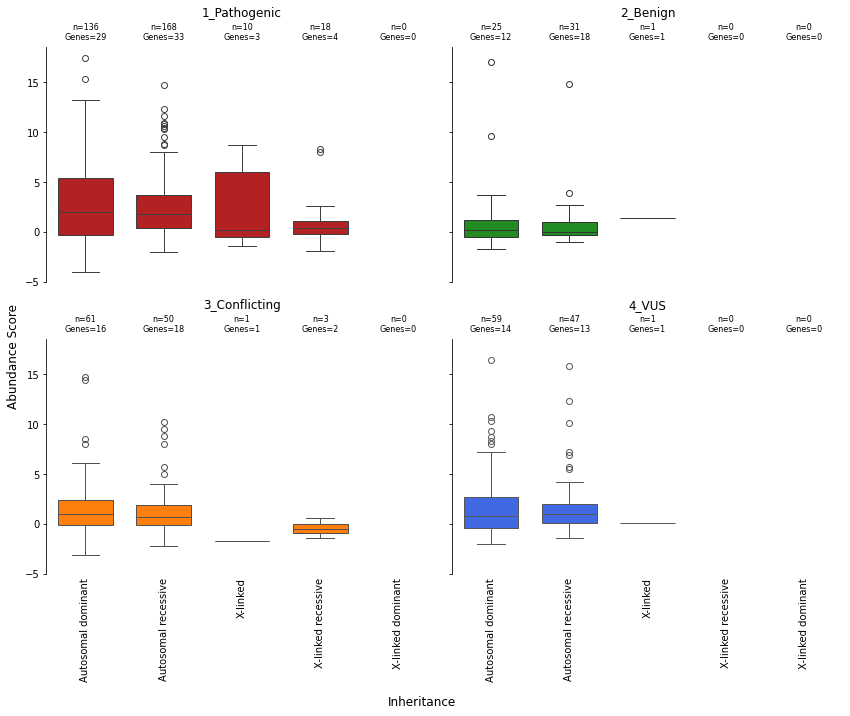

In [23]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

#--- parameters from your original snippet ---
order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]
box_colors = ['forestgreen','silver','turquoise','slateblue','orchid']
palette = dict(zip(order, box_colors))
score = 'abun_score'

clinsig_colors = {
    '1_Pathogenic':   'firebrick',
    '2_Benign':       'forestgreen',
    '3_Conflicting':  'C1',
    '4_VUS':          'royalblue',
}

# drop global NaNs
df_clean = scores.dropna(subset=[score, 'clinvar_clnsig_clean'])

# figure layout
clin_cats = ['1_Pathogenic', '2_Benign',  '3_Conflicting', '4_VUS']
n = len(clin_cats)
ncols = 2
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, nrows*5), sharey=True)
axes = axes.flatten()

for idx, (ax, clin) in enumerate(zip(axes, clin_cats)):
    sub = df_clean[df_clean['clinvar_clnsig_clean']==clin]
    color = clinsig_colors[clin]
    # 1) boxplot
    sns.boxplot(
        x='inheritance', y=score, data=sub,
        order=order, color=color, width=0.7,
        saturation=1, ax=ax
    )
    ax.set_title(clin, pad=30)
    
    ax.set_xlabel('')  # supxlabel handles the axis label

    if idx < ncols:
        # first row: remove xtick labels entirely
        ax.set_xticklabels([])
    else:
        # bottom row: show & rotate them
        ax.set_xticklabels(order, rotation=90)
    
    # ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('')  # label only on first
    
    # 2) stats: all pairwise
    all_pairs = list(combinations(order, 2))
    raw_p = []
    for g1,g2 in all_pairs:
        x = sub.loc[sub.inheritance==g1, score]
        y = sub.loc[sub.inheritance==g2, score]
        # if either group is empty, skip
        if len(x)==0 or len(y)==0:
            raw_p.append(1.0)
        else:
            _, p = mannwhitneyu(x, y, alternative='two-sided')
            raw_p.append(p)
    # FDR correction
    _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')
    
    # 3) annotate significant
    pos = {cat:i for i,cat in enumerate(order)}
    y_max, y_min = sub[score].max(), sub[score].min()
    height = y_max + (y_max-y_min)*0.08
    step   = (y_max-y_min)*0.075
    y_i = 0
    for ((g1,g2), pval) in zip(all_pairs, p_adj):
        if pval < 0.05:
            x1, x2 = pos[g1], pos[g2]
            y = height + y_i*step
            ax.plot([x1, x1, x2, x2],
                    [y, y+step*0.3, y+step*0.3, y],
                    lw=1.2, c='k')
            ax.text((x1+x2)/2, y+step*0.1, "*",
                    ha='center', va='bottom')
            y_i += 1
    
    # 4) annotate counts
    y_min_ax, y_max_ax = ax.get_ylim()
    yrange = y_max_ax - y_min_ax
    y_cnt = y_max_ax + 0.02*yrange
    for i, cat in enumerate(order):
        grp = sub[sub.inheritance == cat]
        n_edges = len(grp)
        n_genes = grp['symbol'].nunique()
        ax.text(
            i, y_cnt,
            f"n={n_edges}\nGenes={n_genes}",
            ha='center', va='bottom', fontsize=8
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.xaxis.set_tick_params(length=0)

# hide any unused axes
for ax in axes[len(clin_cats):]:
    ax.axis('off')

fig.supxlabel("Inheritance")
fig.supylabel("Abundance Score")
plt.tight_layout()
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/2024225762.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/2024225762.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)


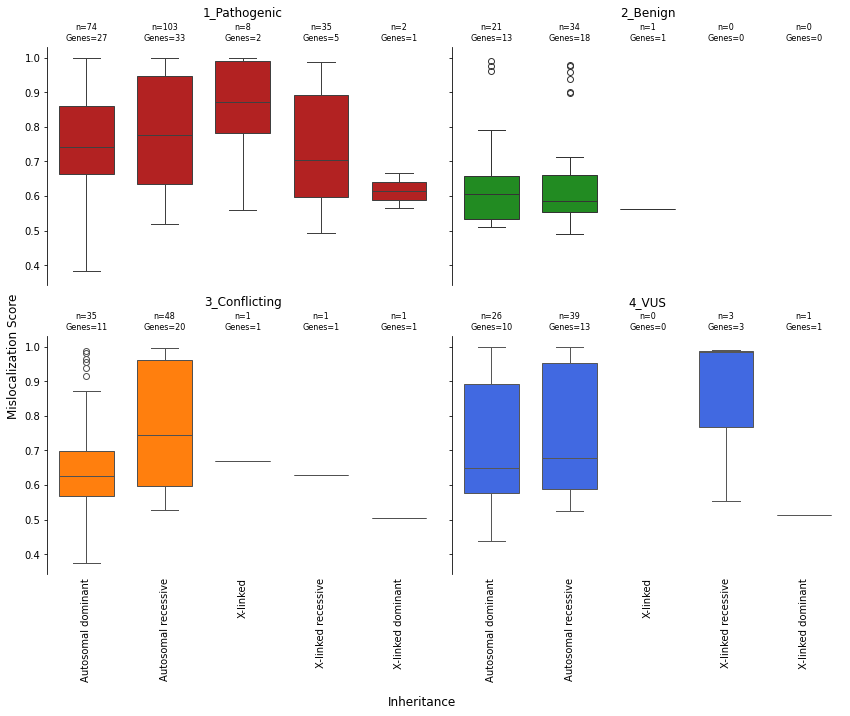

In [24]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

#--- parameters from your original snippet ---
order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]
box_colors = ['forestgreen','silver','turquoise','slateblue','orchid']
palette = dict(zip(order, box_colors))
score = 'misloc_score'

clinsig_colors = {
    '1_Pathogenic':   'firebrick',
    '2_Benign':       'forestgreen',
    '3_Conflicting':  'C1',
    '4_VUS':          'royalblue',
}

# drop global NaNs
df_clean = scores.dropna(subset=[score, 'clinvar_clnsig_clean'])

# figure layout
clin_cats = ['1_Pathogenic', '2_Benign',  '3_Conflicting', '4_VUS']
n = len(clin_cats)
ncols = 2
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, nrows*5), sharey=True)
axes = axes.flatten()

for idx, (ax, clin) in enumerate(zip(axes, clin_cats)):
    sub = df_clean[df_clean['clinvar_clnsig_clean']==clin]
    color = clinsig_colors[clin]
    # 1) boxplot
    sns.boxplot(
        x='inheritance', y=score, data=sub,
        order=order, color=color, width=0.7,
        saturation=1, ax=ax
    )
    ax.set_title(clin, pad=30)
    
    ax.set_xlabel('')  # supxlabel handles the axis label

    if idx < ncols:
        # first row: remove xtick labels entirely
        ax.set_xticklabels([])
    else:
        # bottom row: show & rotate them
        ax.set_xticklabels(order, rotation=90)
    
    # ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('')  # label only on first
    
    # 2) stats: all pairwise
    all_pairs = list(combinations(order, 2))
    raw_p = []
    for g1,g2 in all_pairs:
        x = sub.loc[sub.inheritance==g1, score]
        y = sub.loc[sub.inheritance==g2, score]
        # if either group is empty, skip
        if len(x)==0 or len(y)==0:
            raw_p.append(1.0)
        else:
            _, p = mannwhitneyu(x, y, alternative='two-sided')
            raw_p.append(p)
    # FDR correction
    _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')
    
    # 3) annotate significant
    pos = {cat:i for i,cat in enumerate(order)}
    y_max, y_min = sub[score].max(), sub[score].min()
    height = y_max + (y_max-y_min)*0.08
    step   = (y_max-y_min)*0.075
    y_i = 0
    for ((g1,g2), pval) in zip(all_pairs, p_adj):
        if pval < 0.05:
            x1, x2 = pos[g1], pos[g2]
            y = height + y_i*step
            ax.plot([x1, x1, x2, x2],
                    [y, y+step*0.3, y+step*0.3, y],
                    lw=1.2, c='k')
            ax.text((x1+x2)/2, y+step*0.1, "*",
                    ha='center', va='bottom')
            y_i += 1
    
    # 4) annotate counts
    y_min_ax, y_max_ax = ax.get_ylim()
    yrange = y_max_ax - y_min_ax
    y_cnt = y_max_ax + 0.02*yrange
    for i, cat in enumerate(order):
        grp = sub[sub.inheritance == cat]
        n_edges = len(grp)
        n_genes = grp['symbol'].nunique()
        ax.text(
            i, y_cnt,
            f"n={n_edges}\nGenes={n_genes}",
            ha='center', va='bottom', fontsize=8
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.xaxis.set_tick_params(length=0)

# hide any unused axes
for ax in axes[len(clin_cats):]:
    ax.axis('off')

fig.supxlabel("Inheritance")
fig.supylabel("Mislocalization Score")
plt.tight_layout()
plt.show()


/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/2605947266.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)
/var/folders/ng/d7mydbq105b1ndpt60np34jh0000gn/T/ipykernel_27077/2605947266.py:56: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(order, rotation=90)


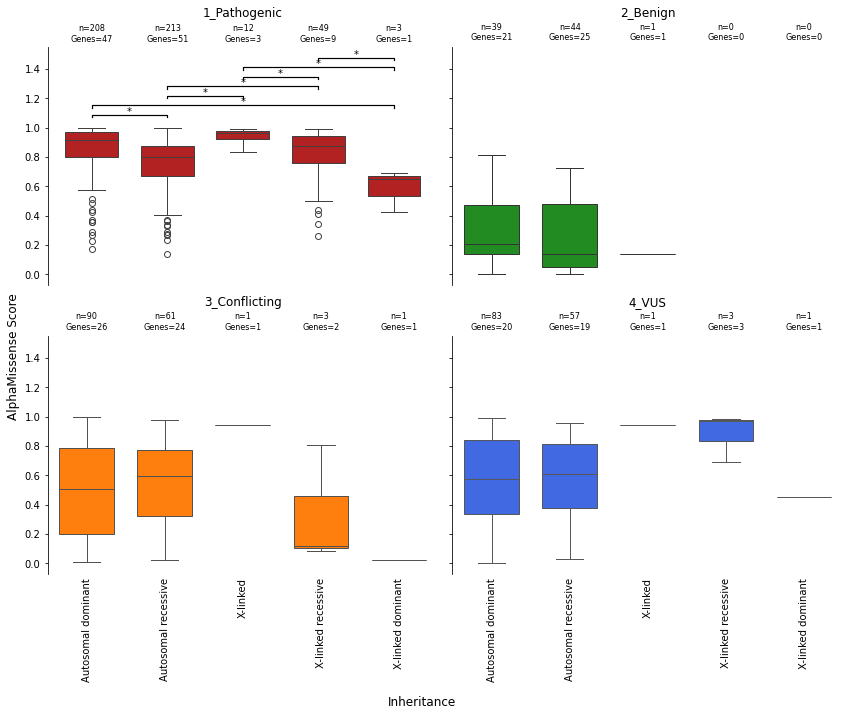

In [25]:
import math
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from scipy.stats import mannwhitneyu
from statsmodels.stats.multitest import multipletests

#--- parameters from your original snippet ---
order = [
    'Autosomal dominant',
    'Autosomal recessive',
    'X-linked',
    'X-linked recessive',
    'X-linked dominant'
]
box_colors = ['forestgreen','silver','turquoise','slateblue','orchid']
palette = dict(zip(order, box_colors))
score = 'ai_score'

clinsig_colors = {
    '1_Pathogenic':   'firebrick',
    '2_Benign':       'forestgreen',
    '3_Conflicting':  'C1',
    '4_VUS':          'royalblue',
}

# drop global NaNs
df_clean = scores.dropna(subset=[score, 'clinvar_clnsig_clean'])

# figure layout
clin_cats = ['1_Pathogenic', '2_Benign',  '3_Conflicting', '4_VUS']
n = len(clin_cats)
ncols = 2
nrows = math.ceil(n / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(12, nrows*5), sharey=True)
axes = axes.flatten()

for idx, (ax, clin) in enumerate(zip(axes, clin_cats)):
    sub = df_clean[df_clean['clinvar_clnsig_clean']==clin]
    color = clinsig_colors[clin]
    # 1) boxplot
    sns.boxplot(
        x='inheritance', y=score, data=sub,
        order=order, color=color, width=0.7,
        saturation=1, ax=ax
    )
    ax.set_title(clin, pad=30)
    
    ax.set_xlabel('')  # supxlabel handles the axis label

    if idx < ncols:
        # first row: remove xtick labels entirely
        ax.set_xticklabels([])
    else:
        # bottom row: show & rotate them
        ax.set_xticklabels(order, rotation=90)
    
    # ax.tick_params(axis='x', rotation=90)
    ax.set_xlabel('')
    ax.set_ylabel('')  # label only on first
    
    # 2) stats: all pairwise
    all_pairs = list(combinations(order, 2))
    raw_p = []
    for g1,g2 in all_pairs:
        x = sub.loc[sub.inheritance==g1, score]
        y = sub.loc[sub.inheritance==g2, score]
        # if either group is empty, skip
        if len(x)==0 or len(y)==0:
            raw_p.append(1.0)
        else:
            _, p = mannwhitneyu(x, y, alternative='two-sided')
            raw_p.append(p)
    # FDR correction
    _, p_adj, _, _ = multipletests(raw_p, method='fdr_bh')
    
    # 3) annotate significant
    pos = {cat:i for i,cat in enumerate(order)}
    y_max, y_min = sub[score].max(), sub[score].min()
    height = y_max + (y_max-y_min)*0.08
    step   = (y_max-y_min)*0.075
    y_i = 0
    for ((g1,g2), pval) in zip(all_pairs, p_adj):
        if pval < 0.05:
            x1, x2 = pos[g1], pos[g2]
            y = height + y_i*step
            ax.plot([x1, x1, x2, x2],
                    [y, y+step*0.3, y+step*0.3, y],
                    lw=1.2, c='k')
            ax.text((x1+x2)/2, y+step*0.1, "*",
                    ha='center', va='bottom')
            y_i += 1
    
    # 4) annotate counts
    y_min_ax, y_max_ax = ax.get_ylim()
    yrange = y_max_ax - y_min_ax
    y_cnt = y_max_ax + 0.02*yrange
    for i, cat in enumerate(order):
        grp = sub[sub.inheritance == cat]
        n_edges = len(grp)
        n_genes = grp['symbol'].nunique()
        ax.text(
            i, y_cnt,
            f"n={n_edges}\nGenes={n_genes}",
            ha='center', va='bottom', fontsize=8
        )
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.xaxis.set_tick_params(length=0)

# hide any unused axes
for ax in axes[len(clin_cats):]:
    ax.axis('off')

fig.supxlabel("Inheritance")
fig.supylabel("AlphaMissense Score")
plt.tight_layout()
plt.show()


# gencc

In [26]:
gencc_df = pd.read_csv('/Users/user_42/Downloads/gencc-submissions.tsv', sep='\t')
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [29]:
gencc_df.moi_title.unique()

array(['Autosomal dominant', 'Autosomal recessive', 'X-linked', 'Unknown',
       'Y-linked inheritance', 'Mitochondrial', 'Semidominant',
       'X-linked recessive'], dtype=object)

In [38]:
gencc_df[gencc_df['disease_original_curie'] == gencc_df['submitted_as_disease_id']]

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_submitter_name,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,Ambry Genetics,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,Ambry Genetics,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,Ambry Genetics,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,Ambry Genetics,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,Orphanet,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06


In [40]:
gencc_df['OMIM_ID'] = gencc_df['submitted_as_disease_id'].str.split(':').str[1]
gencc_df

,uuid,gene_curie,gene_symbol,disease_curie,disease_title,disease_original_curie,disease_original_title,classification_curie,classification_title,moi_curie,...,submitted_as_classification_id,submitted_as_classification_name,submitted_as_date,submitted_as_public_report_url,submitted_as_notes,submitted_as_pmids,submitted_as_assertion_criteria_url,submitted_as_submission_id,submitted_run_date,OMIM_ID
0,GENCC_000101-HGNC_10896-OMIM_182212-HP_0000006...,HGNC:10896,SKI,MONDO:0008426,Shprintzen-Goldberg syndrome,OMIM:182212,Shprintzen-Goldberg syndrome,GENCC:100001,Definitive,HP:0000006,...,GENCC:100001,Definitive,2018-03-30 13:31:56,NaN,NaN,NaN,PMID: 28106320,1034,2020-12-24,182212
1,GENCC_000101-HGNC_16636-OMIM_171300-HP_0000006...,HGNC:16636,KIF1B,MONDO:0008233,pheochromocytoma,OMIM:171300,"{Pheochromocytoma, susceptibility to}",GENCC:100003,Moderate,HP:0000006,...,GENCC:100003,Moderate,2019-12-04 13:30:43,NaN,NaN,NaN,PMID: 28106320,69237,2020-12-24,171300
2,GENCC_000101-HGNC_16636-OMIM_118210-HP_0000006...,HGNC:16636,KIF1B,MONDO:0007308,Charcot-Marie-Tooth disease type 2A1,OMIM:118210,"Charcot-Marie-Tooth disease, type 2A1",GENCC:100004,Limited,HP:0000006,...,GENCC:100004,Limited,2024-10-15 12:08:25,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,61327,2025-01-17,118210
3,GENCC_000101-HGNC_17939-OMIM_617532-HP_0000007...,HGNC:17939,SLC45A1,MONDO:0044322,intellectual developmental disorder with neuro...,OMIM:617532,Intellectual developmental disorder with neuro...,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2024-09-26 12:08:38,NaN,NaN,NaN,https://www.ncbi.nlm.nih.gov/pmc/articles/PMC5...,17305,2025-01-17,617532
4,GENCC_000101-HGNC_11071-OMIM_616291-HP_0000007...,HGNC:11071,SLC9A1,MONDO:0014572,Lichtenstein-Knorr syndrome,OMIM:616291,Lichtenstein-Knorr syndrome,GENCC:100004,Limited,HP:0000007,...,GENCC:100004,Limited,2018-08-31 13:32:02,NaN,NaN,NaN,PMID: 28106320,1705,2020-12-24,616291
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21213,GENCC_000110-HGNC_9381-Orphanet_289-HP_0000007...,HGNC:9381,PRKACB,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACB_Orphanet:289_HP:0000007,2025-03-06,289
21214,GENCC_000110-HGNC_9380-Orphanet_289-HP_0000007...,HGNC:9380,PRKACA,MONDO:0009162,Ellis-van Creveld syndrome,Orphanet:289,Orphanet:289,GENCC:100009,Supportive,HP:0000007,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,33058759,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_PRKACA_Orphanet:289_HP:0000007,2025-03-06,289
21215,GENCC_000110-HGNC_7489-Orphanet_1349-HP_000142...,HGNC:7489,MT-TK,MONDO:0015283,maternally-inherited cardiomyopathy and hearin...,Orphanet:1349,Orphanet:1349,GENCC:100009,Supportive,HP:0001427,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,8651277,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_MT-TK_Orphanet:1349_HP:0001427,2025-03-06,1349
21216,GENCC_000110-HGNC_358-Orphanet_963-HP_0000005-...,HGNC:358,AIP,MONDO:0019933,acromegaly,Orphanet:963,Orphanet:963,GENCC:100009,Supportive,HP:0000005,...,GENCC:100009,Supportive,2025-03-06 00:00:00,NaN,NaN,20530095,https://www.orpha.net/orphacom/cahiers/docs/GB...,GENCC_000110_AIP_Orphanet:963_HP:0000005,2025-03-06,963


In [41]:
gencc_d = gencc_df.set_index('OMIM_ID')['moi_title']
gencc_d

OMIM_ID
182212     Autosomal dominant
171300     Autosomal dominant
118210     Autosomal dominant
617532    Autosomal recessive
616291    Autosomal recessive
                 ...         
289       Autosomal recessive
289       Autosomal recessive
1349            Mitochondrial
963                   Unknown
963                   Unknown
Name: moi_title, Length: 21218, dtype: object

In [42]:
inheritance_mapping_df

,orf_id,symbol,nt_change,aa_change,inheritance_clean,allele_0
0,2,GBA,160G>C,Val54Leu,NaN,GBA_Val54Leu
1,2,GBA,670C>T,Leu224Phe,NaN,GBA_Leu224Phe
2,2,GBA,887G>A,Arg296Gln,Conflicting,GBA_Arg296Gln
3,2,GBA,1448T>C,Leu483Pro,Conflicting,GBA_Leu483Pro
4,25,SLC9A3R1,328C>G,Leu110Val,Autosomal dominant,SLC9A3R1_Leu110Val
...,...,...,...,...,...,...
8483,8999,TTR,355G>A,Asp119Asn,Autosomal dominant,TTR_Asp119Asn
8484,7323,PMP22,152A>G,His51Arg,NaN,PMP22_His51Arg
8485,2651,CLN6,89G>C,Gly30Ala,NaN,CLN6_Gly30Ala
8486,7323,PMP22,403G>A,Ala135Thr,Autosomal dominant,PMP22_Ala135Thr
